<a href="https://colab.research.google.com/github/Edohkindness1/california-housing-regression/blob/main/california_housing_regression_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Why the median imputer. total_bedrooms is skewed, so the median is more robust than the mean.

In [15]:
# Imports and data loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [17]:
df.isna().sum()  # total_bedrooms has missing values

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [18]:
# Engineer interaction features
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df["income_x_rooms"] = df["median_income"] * df["rooms_per_household"]  # an interaction term

Point to the heatmap, and explain that Ridge spreads weight across correlated features while Lasso picks one and drops the rest.

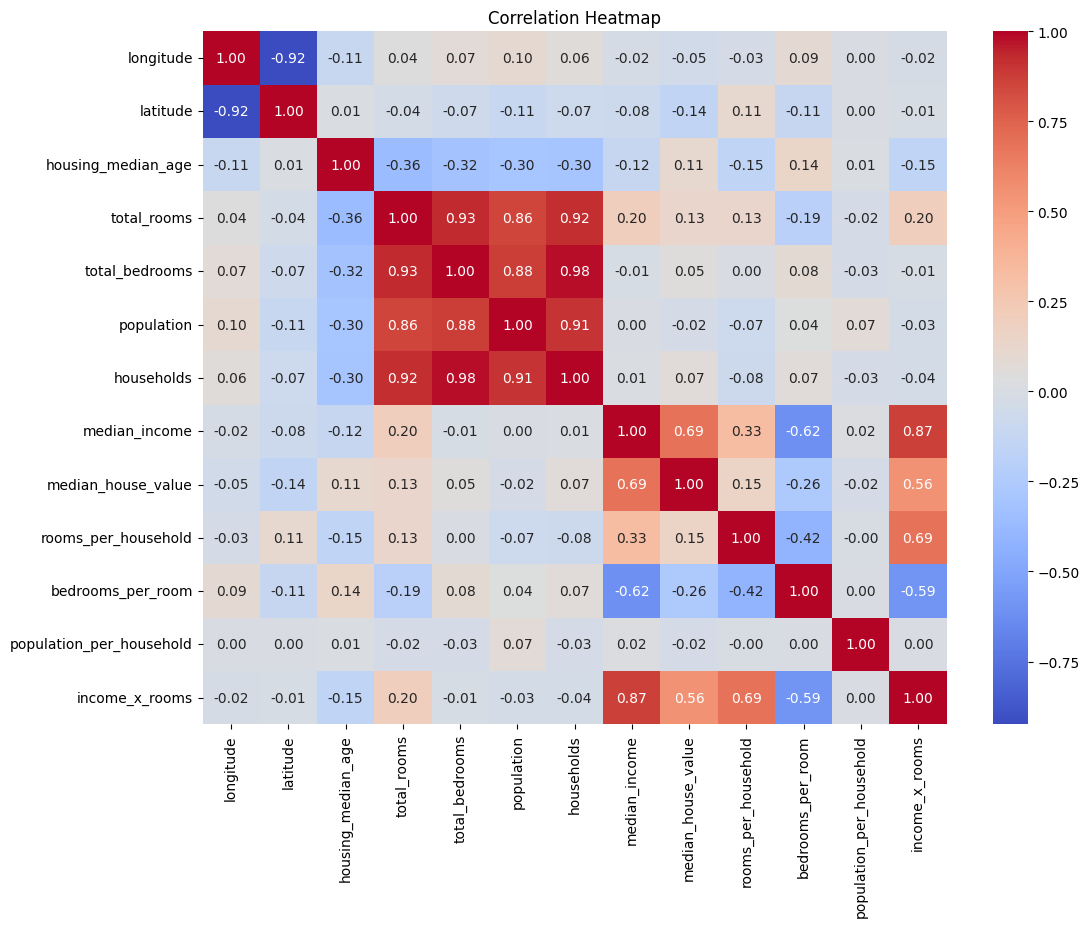

In [19]:
# Correlation heatmap (multicollinearity check)
plt.figure(figsize=(12, 9))
sns.heatmap(df.drop(columns="ocean_proximity").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [20]:
# Split, then build the preprocessing pipeline
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = ["ocean_proximity"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [21]:
# Fit ols, ridge and lasso with GridSearchCV
ols = Pipeline([("prep", preprocess), ("model", LinearRegression())]).fit(X_train, y_train)

ridge_grid = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", Ridge())]),
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
).fit(X_train, y_train)

lasso_grid = GridSearchCV(
    Pipeline([("prep", preprocess), ("model", Lasso(max_iter=20000))]),
    param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1
).fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Lasso alpha:", lasso_grid.best_params_)

Best Ridge alpha: {'model__alpha': 1}
Best Lasso alpha: {'model__alpha': 1}


Explain which model won, and by how much. The three will likely be very close, because there are enough rows (about 20,000) and the features are few. Say so honestly. If the results are nearly equal, that is a valid finding.

In [22]:
# metrics comparison
models = {"OLS": ols, "Ridge": ridge_grid.best_estimator_, "Lasso": lasso_grid.best_estimator_}
results = []
for name, m in models.items():
    pred = m.predict(X_test)
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
    })
results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,RMSE,MAE,R2
Model,,,
OLS,68917.317,49709.540,0.638
Ridge,68925.957,49715.841,0.637
Lasso,68918.676,49710.272,0.638


Note any pattern. This dataset caps median_house_value at 500,000, so you will see a horizontal band of points in predicted vs actual. That is a data limitation, and pointing it out shows real understanding.

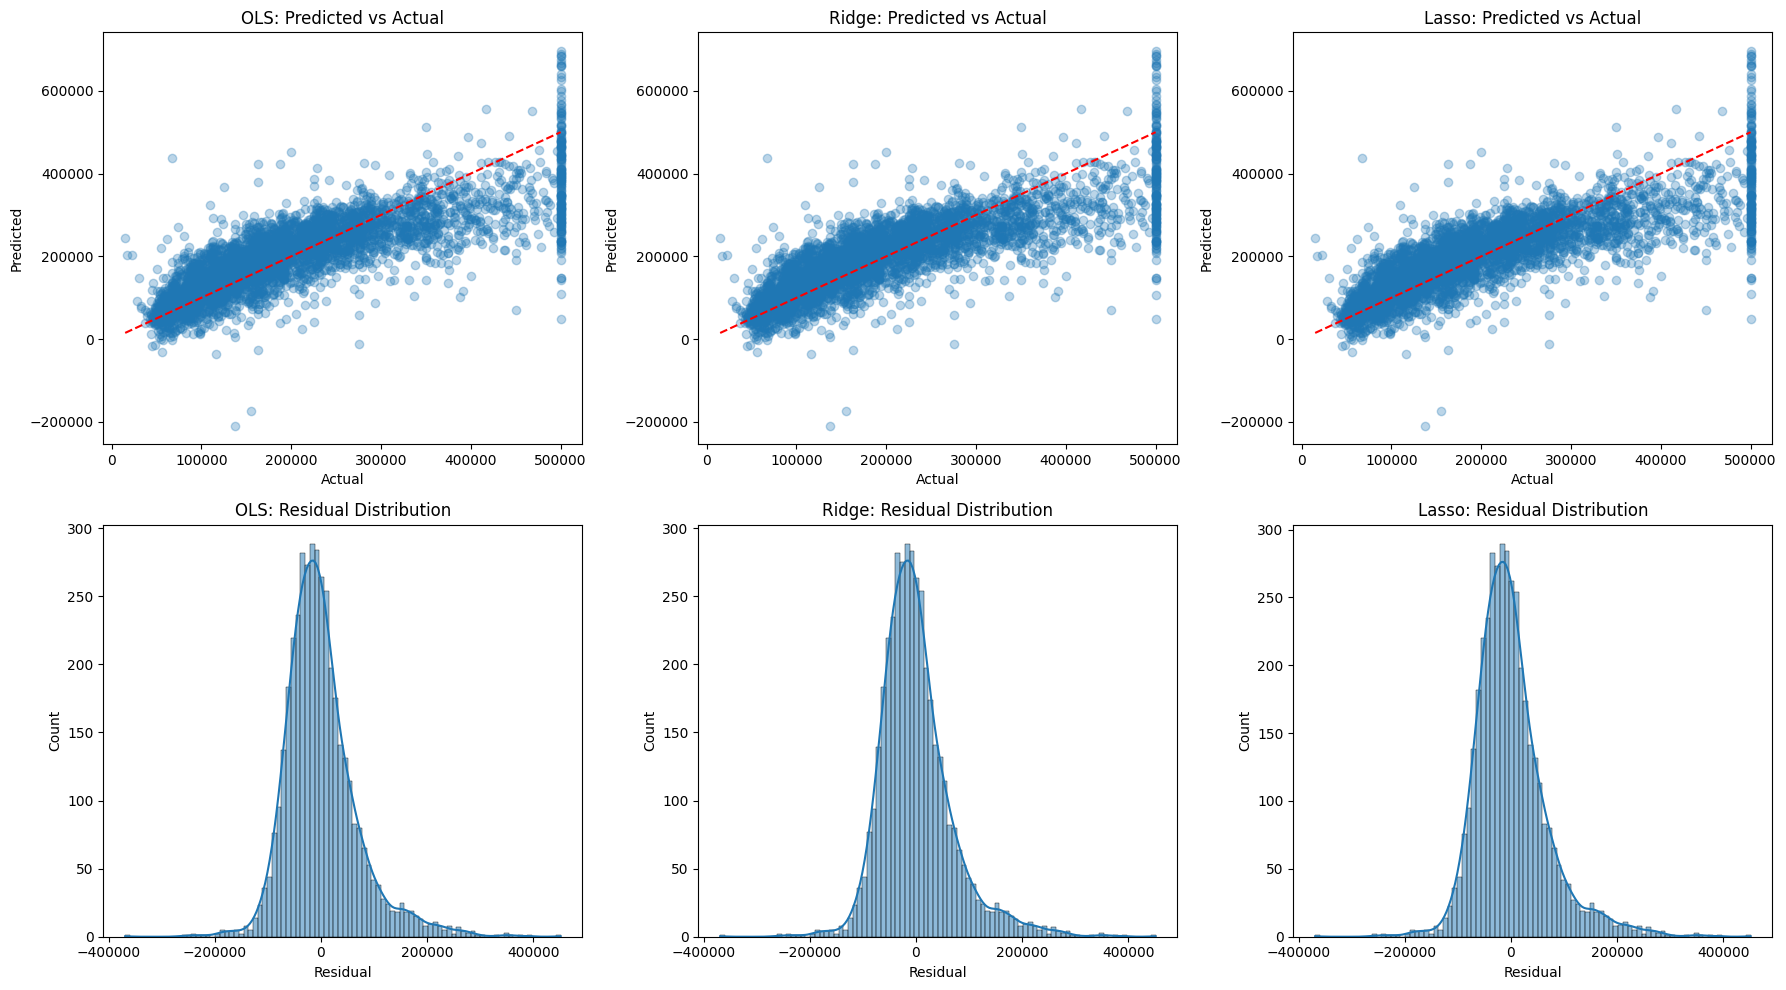

In [23]:
# Predicted vs actual and residual plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, (name, m) in enumerate(models.items()):
    pred = m.predict(X_test)
    resid = y_test - pred

    axes[0, i].scatter(y_test, pred, alpha=0.3)
    axes[0, i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
    axes[0, i].set(title=f"{name}: Predicted vs Actual", xlabel="Actual", ylabel="Predicted")

    sns.histplot(resid, kde=True, ax=axes[1, i])
    axes[1, i].set(title=f"{name}: Residual Distribution", xlabel="Residual")
plt.tight_layout()
plt.show()

In [24]:
# this Show what Lasso did
feature_names = lasso_grid.best_estimator_["prep"].get_feature_names_out()
coefs = pd.DataFrame({
    "feature": feature_names,
    "OLS": ols["model"].coef_,
    "Ridge": ridge_grid.best_estimator_["model"].coef_,
    "Lasso": lasso_grid.best_estimator_["model"].coef_,
}).set_index("feature").round(1)
coefs

,OLS,Ridge,Lasso
feature,,,
num__longitude,-55498.4,-55448.9,-55482.4
num__latitude,-55796.6,-55751.0,-55782.9
num__housing_median_age,14260.8,14265.1,14259.6
num__total_rooms,7124.0,7116.7,7112.6
num__total_bedrooms,6999.0,7105.1,7015.9
num__population,-45386.7,-45358.5,-45374.8
num__households,36348.7,36223.1,36330.5
num__median_income,92154.7,92083.6,92126.2
num__rooms_per_household,14106.9,14061.5,14089.5
